# load model

In [1]:
import pandas as pd
import numpy as np
import time
from tqdm import tqdm
from collections import defaultdict
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy.special import expit # Sigmoid function

In [2]:
ratings_full = pd.read_csv('../data/processed_full/user_item_processed_data.csv')
user_df = pd.read_csv('../data/processed_full/user_features.csv')
item_df = pd.read_csv('../data/processed_full/item_features.csv')

print("Data simulation complete.")
print("\nRatings Full DF shape:", ratings_full.shape)
print("\nItem Features DF shape:", item_df.shape)
print("\nUser Features DF shape:", user_df.shape)
ratings_full.head(5)

Data simulation complete.

Ratings Full DF shape: (1400102, 109)

Item Features DF shape: (27197, 115)

User Features DF shape: (46660, 115)


,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text_emb_0,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,1521,19,1.0,NaN,1.0,NaN,1.0,1.0,NaN,-0.041622,...,0.051783,0.090821,0.023550,-0.028458,0.022709,-0.017830,0.030984,-0.066530,-0.004420,0.022615
1,1524,19,1.0,NaN,NaN,1.0,1.0,NaN,0.6,0.094268,...,0.007869,-0.021458,-0.011069,0.033729,-0.014652,0.031356,0.019260,-0.038565,-0.017441,0.011813
2,1527,19,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.226007,...,0.035656,0.022072,0.031577,-0.085225,-0.019208,0.009750,-0.041887,0.036383,0.069358,0.071002
3,1529,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.026531,...,0.003374,0.041171,0.008375,0.020658,0.000111,-0.012515,-0.019410,-0.014252,0.023997,0.030726
4,1530,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.133377,...,-0.012842,-0.004858,0.077540,-0.057574,0.024631,-0.011781,-0.032293,-0.060140,0.048414,0.012466


In [3]:
# load the model
with open('lightfm_hybrid_model_75e_256d.pkl', 'rb') as f:
    loaded_checkpoint = pickle.load(f)
    
model = loaded_checkpoint['model']
user_id_map = loaded_checkpoint['user_id_map']
item_id_map = loaded_checkpoint['item_id_map']
inv_user_id_map = loaded_checkpoint['inv_user_id_map']
inv_item_id_map = loaded_checkpoint['inv_item_id_map']
user_features = loaded_checkpoint['user_features']
item_features = loaded_checkpoint['item_features']
train_interactions = loaded_checkpoint['train_interactions']
test_interactions = loaded_checkpoint['test_interactions']

/Users/maksiuuuuuuu/miniconda3/envs/recsys_env/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [4]:
k_values = [10, 20, 50, 100]
train_interactions_csr = train_interactions.tocsr()
test_interactions_csr = test_interactions.tocsr()

# Pre-calculate true items for test users (as you did)
true_items_per_user = {
    u: dict(zip(test_interactions_csr[u].indices, test_interactions_csr[u].data))
    for u in range(test_interactions_csr.shape[0]) if test_interactions_csr[u].nnz > 0
}

test_user_indices = list(true_items_per_user.keys())
all_item_indices = np.arange(len(item_id_map))

# # --- Accumulators for Metrics ---
# ndcg_scores = {k: [] for k in k_values}
# hit_counts = {k: 0 for k in k_values}
# unique_items_recommended = {k: set() for k in k_values}
# recommendation_counts = {k: defaultdict(int) for k in k_values} # For Diversity
# total_users_evaluated = 0

In [5]:
# --- CONFIGURATION ---
EVAL_POOL_SIZE = 25000   # Large enough to minimize group overlap
N_GROUPS_PER_SIZE = 5000 # Large enough for smooth Confidence Intervals
GROUP_SIZES = [4, 6, 8, 10, 12, 15]
TOP_K = 100
strategies = ['additive', 'least_misery', 'most_pleasure']
rng = np.random.default_rng(42)

In [6]:
# 1. Select the pool of users
# We filter for users who actually exist in the test set mapping
valid_test_users = list(true_items_per_user.keys())

if len(valid_test_users) > EVAL_POOL_SIZE:
    # Randomly sample without replacement
    eval_user_ids = np.random.choice(valid_test_users, size=EVAL_POOL_SIZE, replace=False)
else:
    eval_user_ids = np.array(valid_test_users)

print(f"Preparing evaluation pool with {len(eval_user_ids)} users...")

Preparing evaluation pool with 25000 users...


## Here we are precalculating rankings for all user! - decoupled approach!

In [7]:
# 2. Pre-calculate Scores (Batch Prediction)
# This prevents predicting millions of times inside the loop
n_items = len(item_id_map)
user_indices_repeat = np.repeat(eval_user_ids, n_items)
item_indices_tile = np.tile(np.arange(n_items), len(eval_user_ids))

print("Running batch prediction (this might take 30-60 seconds)...")
flat_scores = model.predict(
    user_indices_repeat, 
    item_indices_tile, 
    user_features=user_features, 
    item_features=item_features,
    num_threads=12
)

# Reshape to (n_pool_users, n_items)
precalc_scores = flat_scores.reshape(len(eval_user_ids), n_items)

Running batch prediction (this might take 30-60 seconds)...


In [8]:
# 3. Pre-calculate Training Masks
# We need to know which items each user has already seen to exclude them.
print("Building training masks...")
train_mask = np.zeros(precalc_scores.shape, dtype=bool)

# We need to map Real User ID -> Index in our precalc matrix (0 to 4999)
pool_id_to_index = {uid: i for i, uid in enumerate(eval_user_ids)}

for real_uid in eval_user_ids:
    matrix_idx = pool_id_to_index[real_uid]
    # Get items seen in training
    seen_items = train_interactions_csr[real_uid].indices
    train_mask[matrix_idx, seen_items] = True

print("Pre-calculation complete. Ready for Simulation.")

Building training masks...
Pre-calculation complete. Ready for Simulation.


In [9]:
def aggregate_scores(group_scores, strategy):
    """
    group_scores: (group_size, n_items) array
    """
    if strategy == 'additive': # Average
        return np.mean(group_scores, axis=0)
    
    elif strategy == 'least_misery': # Min
        return np.min(group_scores, axis=0)
    
    elif strategy == 'most_pleasure': # Max
        return np.max(group_scores, axis=0)
    

# Run & Evaluate Rundom Groups (OLD)

In [10]:
results = []
# strategies = ['additive', 'approval_voting', 'least_misery', 'most_pleasure']

print(f"Starting Simulation: {N_GROUPS_PER_SIZE} groups per size...")

for size in GROUP_SIZES:
    # Use tqdm to track progress
    for _ in tqdm(range(N_GROUPS_PER_SIZE), desc=f"Simulating Size {size}"):
        
        # 1. Sample Group
        # We pick indices from our pool (0 to 4999)
        group_pool_indices = np.random.choice(len(eval_user_ids), size=size, replace=False)
        group_real_ids = eval_user_ids[group_pool_indices]
        
        # 2. Extract Data
        # Shape: (size, n_items)
        group_scores = precalc_scores[group_pool_indices]
        group_masks = train_mask[group_pool_indices]
        
        # 3. Combined Mask (If ANYONE saw it, remove it)
        final_mask = np.any(group_masks, axis=0)
        
        for strat in strategies:
            # 4. Aggregate
            final_scores = aggregate_scores(group_scores, strat)
            
            # 5. Apply Mask (Block seen items)
            final_scores[final_mask] = -np.inf
            
            # 6. Get Top K Items
            # We need indices of the winners
            top_items = np.argsort(-final_scores)[:TOP_K]
            
            # 7. Evaluate (Group nDCG)
            # Calculate nDCG for each member individually, then average
            member_ndcgs = []
            
            for i, user_id in enumerate(group_real_ids):
                true_items = true_items_per_user[user_id]
                
                # Calculate nDCG for this member
                dcg = 0.0
                idcg = 0.0
                
                # DCG part
                for rank, item_idx in enumerate(top_items):
                    if item_idx in true_items:
                        dcg += true_items[item_idx] / np.log2(rank + 2)
                
                # IDCG part (Ideal ranking for this specific user)
                sorted_true = sorted(true_items.values(), reverse=True)
                for rank, val in enumerate(sorted_true[:TOP_K]):
                    idcg += val / np.log2(rank + 2)
                
                ndcg = (dcg / idcg) if idcg > 0 else 0.0
                member_ndcgs.append(ndcg)
            
            # 8. Store Result
            results.append({
                'Group_Size': size,
                'Strategy': strat,
                'nDCG': np.mean(member_ndcgs)
            })

# Create DataFrame
df_results = pd.DataFrame(results)
print("Simulation finished.")

Starting Simulation: 5000 groups per size...


Simulating Size 4:   0%|          | 0/5000 [00:00<?, ?it/s]


TypeError: 'NoneType' object does not support item assignment

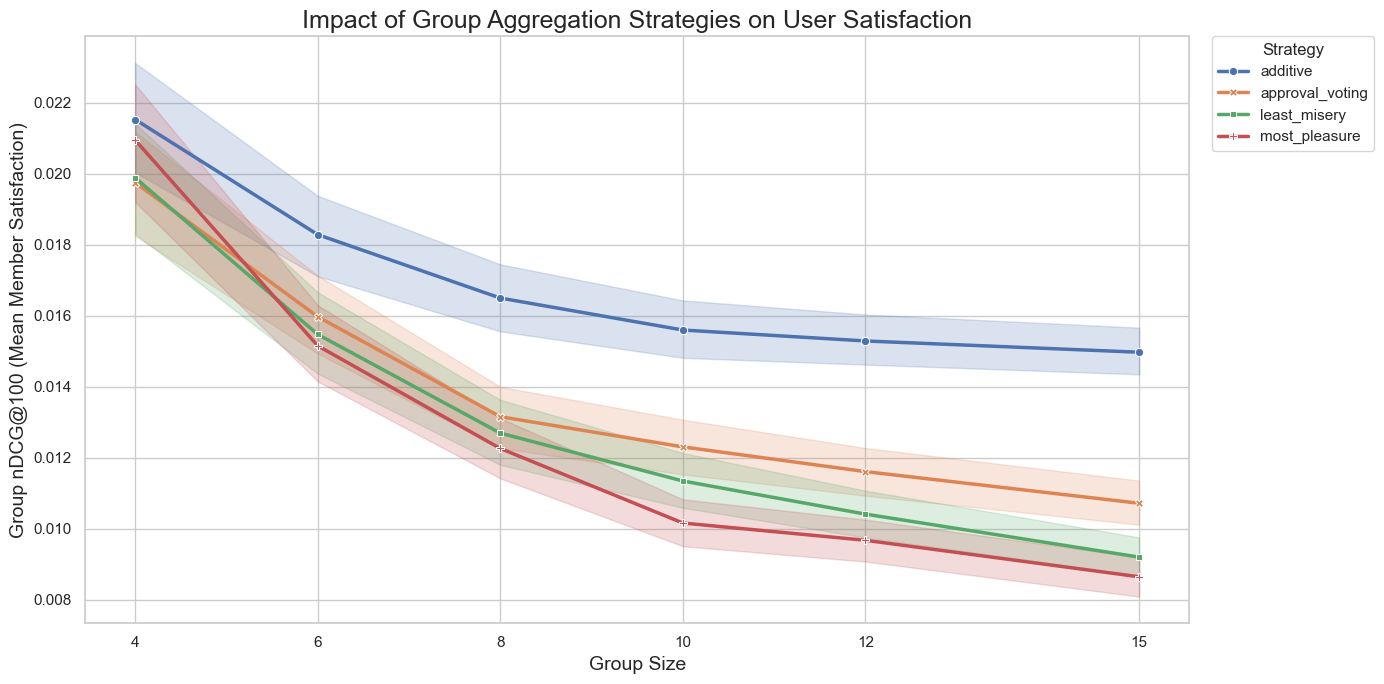


Detailed Statistical Summary:


mean       std  min       max
Group_Size Strategy                                          
4          additive         0.021521  0.024929  0.0  0.156329
           approval_voting  0.019743  0.024677  0.0  0.156329
           least_misery     0.019879  0.024844  0.0  0.152636
           most_pleasure    0.020942  0.026633  0.0  0.249547
6          additive         0.018279  0.019022  0.0  0.144623
           approval_voting  0.015968  0.018709  0.0  0.169407
           least_misery     0.015469  0.018126  0.0  0.111676
           most_pleasure    0.015148  0.017972  0.0  0.129172
8          additive         0.016493  0.015747  0.0  0.117590
           approval_voting  0.013152  0.014500  0.0  0.117965
           least_misery     0.012690  0.014971  0.0  0.087601
           most_pleasure    0.012256  0.014152  0.0  0.076060
10         additive         0.015593  0.013103  0.0  0.095074
           approval_voting  0.012302  0.012069  0.0  0.095130
           least_misery     0.011341  0.011807  0.0  0.104246
           most_pleasure    0.010157  0.010736  0.0  0.065188
12         additive         0.015285  0.011423  0.0  0.079514
           approval_voting  0.011606  0.010691  0.0  0.056842
           least_misery     0.010408  0.010865  0.0  0.076190
           most_pleasure    0.009672  0.009890  0.0  0.053113
15         additive         0.014967  0.010948  0.0  0.081117
           approval_voting  0.010714  0.010045  0.0  0.068856
           least_misery     0.009197  0.009324  0.0  0.056781
           most_pleasure    0.008643  0.008750  0.0  0.047635

In [ ]:
import matplotlib.pyplot as plt
# Set up plotting
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(14, 7))

# Draw Box Plot + Swarm or simple Bar with Error Bars
# Using Lineplot is often cleaner for "Size vs Performance" comparison
ax = sns.lineplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy",
    style="Strategy",
    markers=True,
    dashes=False,
    linewidth=2.5,
    errorbar=('ci', 95) # 95% Confidence Interval shading
)

plt.title("Impact of Group Aggregation Strategies on User Satisfaction", fontsize=18)
plt.ylabel("Group nDCG@100 (Mean Member Satisfaction)", fontsize=14)
plt.xlabel("Group Size", fontsize=14)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Strategy")
plt.xticks(GROUP_SIZES)
plt.tight_layout()
plt.show()

# --- Statistical Table ---
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].describe()[['mean', 'std', 'min', 'max']]
print("\nDetailed Statistical Summary:")
display(summary)

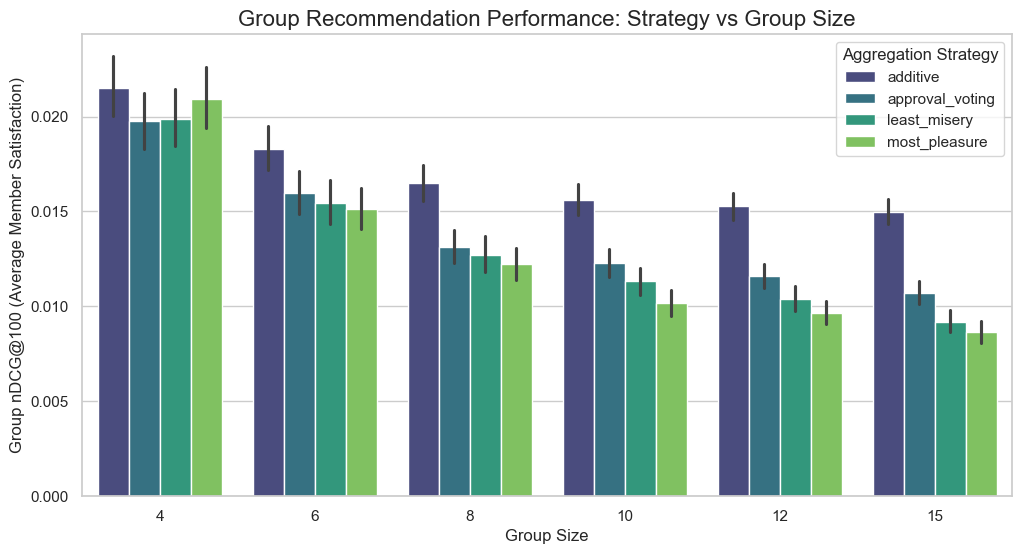


Mean nDCG Scores:


Strategy,additive,approval_voting,least_misery,most_pleasure
Group_Size,,,,
4,0.021521,0.019743,0.019879,0.020942
6,0.018279,0.015968,0.015469,0.015148
8,0.016493,0.013152,0.012690,0.012256
10,0.015593,0.012302,0.011341,0.010157
12,0.015285,0.011606,0.010408,0.009672
15,0.014967,0.010714,0.009197,0.008643


In [ ]:
# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create Barplot
# ci=95 draws the confidence intervals (error bars) automatically
ax = sns.barplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy", 
    palette="viridis",
    errorbar=('ci', 95) 
)

plt.title("Group Recommendation Performance: Strategy vs Group Size", fontsize=16)
plt.ylabel("Group nDCG@100 (Average Member Satisfaction)", fontsize=12)
plt.xlabel("Group Size", fontsize=12)
plt.legend(title="Aggregation Strategy", loc='upper right')
plt.show()

# Print numerical summary
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].mean().unstack()
print("\nMean nDCG Scores:")
display(summary)

# Run & Evaluate Random and Similarity-Based groups

In [11]:
def calculate_group_ndcg(group_real_ids, top_k_items, k, true_items_map):
    """Calculates average nDCG for the group members."""
    member_ndcgs = []
    
    for uid in group_real_ids:
        true_items = true_items_map.get(uid, {})
        if not true_items: continue
            
        dcg = 0.0
        idcg = 0.0
        
        # DCG
        for rank, item_idx in enumerate(top_k_items):
            if item_idx in true_items:
                # Assuming binary relevance (1 or 0) for simplicity in implicit feedback
                dcg += 1.0 / np.log2(rank + 2)
        
        # IDCG
        n_poss = min(len(true_items), k)
        for rank in range(n_poss):
            idcg += 1.0 / np.log2(rank + 2)
            
        member_ndcgs.append(dcg / idcg if idcg > 0 else 0)
        
    return np.mean(member_ndcgs) if member_ndcgs else 0

In [12]:
from sklearn.cluster import KMeans
from collections import defaultdict

def get_similarity_groups(model, user_features, pool_ids, size, n_groups):
    """Generates groups based on latent feature clusters."""
    # Get embeddings only for the pool
    _, all_embeddings = model.get_user_representations(features=user_features)
    pool_embeddings = all_embeddings[pool_ids]
    
    # Cluster
    # We want clusters roughly the size of the target group size
    # But for robustness, let's create slightly larger clusters and sample from them
    n_clusters = max(1, len(pool_ids) // (size * 2)) 
    kmeans = KMeans(n_clusters=n_clusters, n_init=5, random_state=42)
    labels = kmeans.fit_predict(pool_embeddings)
    
    cluster_map = defaultdict(list)
    for idx, label in enumerate(labels):
        cluster_map[label].append(pool_ids[idx])
        
    groups = []
    cluster_keys = list(cluster_map.keys())
    
    count = 0
    while count < n_groups:
        # Pick a random cluster
        c_key = random.choice(cluster_keys)
        members = cluster_map[c_key]
        
        if len(members) >= size:
            # Sample users from this similar cluster
            groups.append(random.sample(members, size))
            count += 1
            
    return groups

def get_random_groups(pool_ids, size, n_groups):
    groups = []
    pool = list(pool_ids)
    for _ in range(n_groups):
        groups.append(random.sample(pool, size))
    return groups

In [14]:
# --- MAIN SIMULATION LOOP ---
results_data = []

print("Starting Simulation...")

for g_size in GROUP_SIZES:
    print(f"\nProcessing Group Size: {g_size}")
    
    # 1. Generate Groups
    # A. Random
    rand_groups = get_random_groups(eval_user_ids, g_size, N_GROUPS_PER_SIZE)
    # B. Similar
    sim_groups = get_similarity_groups(model, user_features, eval_user_ids, g_size, N_GROUPS_PER_SIZE)
    
    # Combine tasks: (GroupType, ListOfGroups)
    tasks = [('Random', rand_groups), ('Similarity', sim_groups)]
    
    for group_type, groups_list in tasks:
        print(f"  > Evaluating {group_type} grouping ({len(groups_list)} groups)...")
        
        for group in tqdm(groups_list, leave=False):
            # 1. Retrieve Pre-calculated scores
            # Map Real UIDs -> Matrix Indices
            matrix_indices = [pool_id_to_index[uid] for uid in group]
            
            # Extract (Group_Size, N_Items)
            g_scores_raw = precalc_scores[matrix_indices]
            
            # 2. Apply Masking (Set seen items to -inf)
            g_mask = train_mask[matrix_indices]
            # We copy to avoid modifying the global precalc array
            g_scores = g_scores_raw.copy()
            g_scores[g_mask] = -np.inf
            
            # 3. Apply Strategies
            for strategy in strategies:
                agg_scores = aggregate_scores(g_scores, strategy)
                
                # 4. Rank
                # argpartition is O(n), faster than argsort O(n log n)
                top_k_unsorted = np.argpartition(-agg_scores, TOP_K)[:TOP_K]
                # Sort just top K for exact nDCG
                top_k_sorted = top_k_unsorted[np.argsort(-agg_scores[top_k_unsorted])]
                
                # 5. Calculate nDCG
                score = calculate_group_ndcg(group, top_k_sorted, TOP_K, true_items_per_user)
                
                results_data.append({
                    'Group_Size': g_size,
                    'Grouping_Method': group_type,
                    'Strategy': strategy,
                    'nDCG': score
                })

df_results = pd.DataFrame(results_data)
print("\nSimulation Complete.")

Starting Simulation...

Processing Group Size: 4
  > Evaluating Random grouping (5000 groups)...


  > Evaluating Similarity grouping (5000 groups)...



Processing Group Size: 6
  > Evaluating Random grouping (5000 groups)...


  > Evaluating Similarity grouping (5000 groups)...



Processing Group Size: 8
  > Evaluating Random grouping (5000 groups)...


  > Evaluating Similarity grouping (5000 groups)...


... (3 outputs left out)

  > Evaluating Similarity grouping (5000 groups)...



Processing Group Size: 15
  > Evaluating Random grouping (5000 groups)...


  > Evaluating Similarity grouping (5000 groups)...



Simulation Complete.


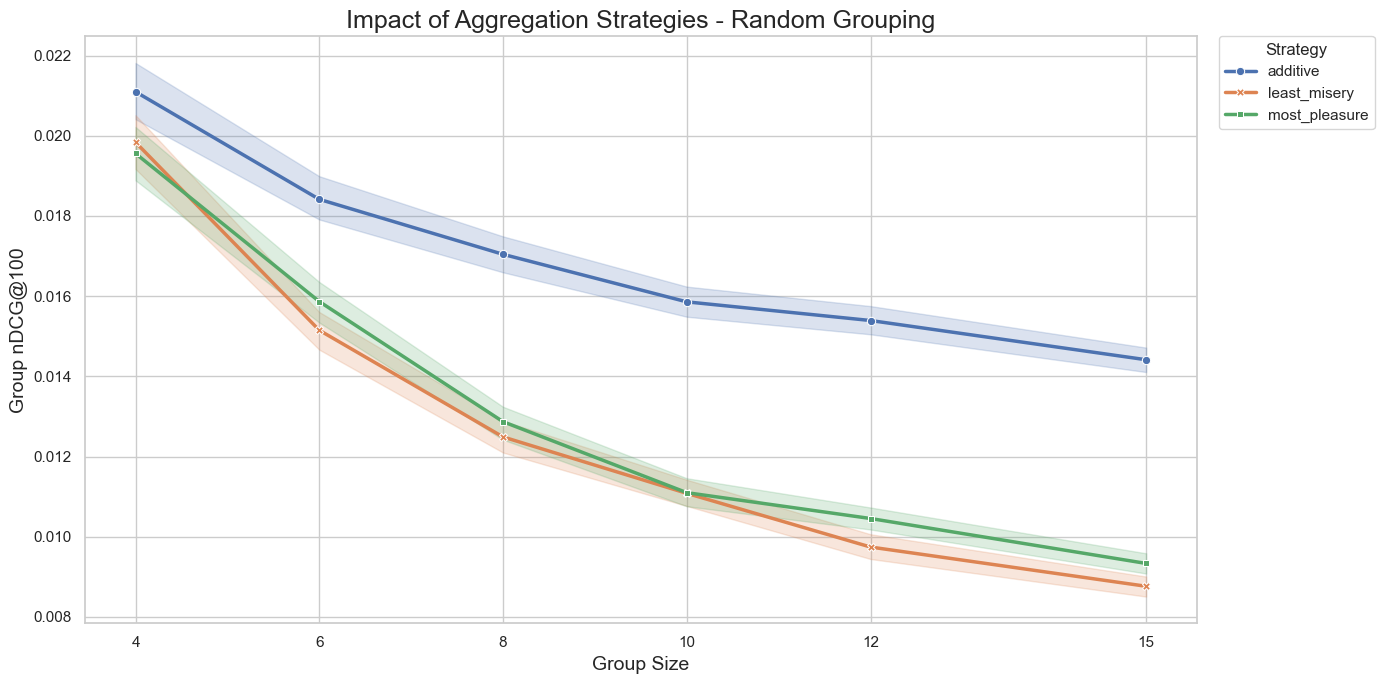

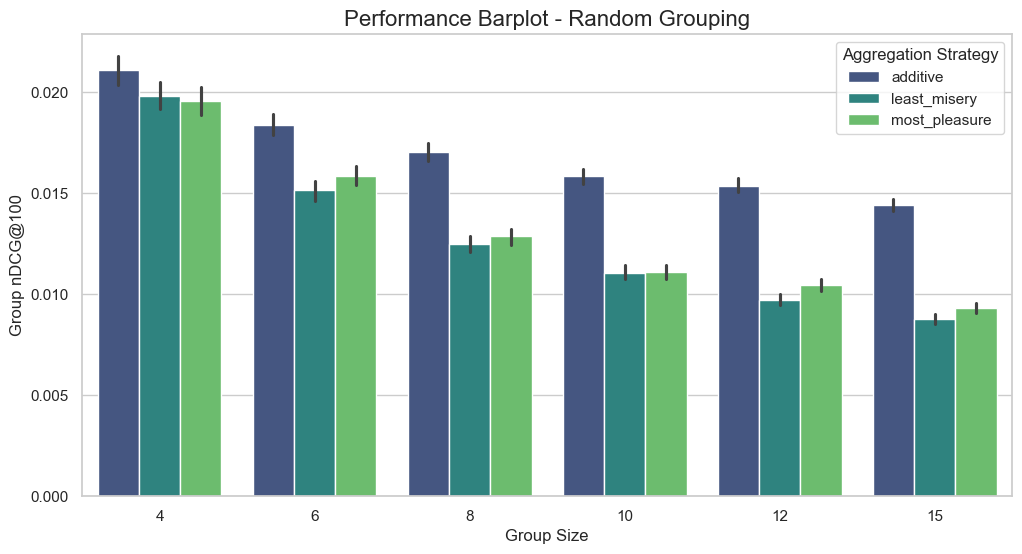


Detailed Statistics for Random Grouping:


mean       std
Group_Size Strategy                         
4          additive       0.021096  0.024942
           least_misery   0.019836  0.025495
           most_pleasure  0.019557  0.024599
6          additive       0.018413  0.019019
           least_misery   0.015149  0.017649
           most_pleasure  0.015865  0.018207
8          additive       0.017042  0.015986
           least_misery   0.012488  0.014295
           most_pleasure  0.012868  0.014440
10         additive       0.015857  0.013526
           least_misery   0.011082  0.012253
           most_pleasure  0.011099  0.011982
12         additive       0.015391  0.012354
           least_misery   0.009743  0.010432
           most_pleasure  0.010454  0.010694
15         additive       0.014413  0.010720
           least_misery   0.008764  0.008830
           most_pleasure  0.009334  0.009051

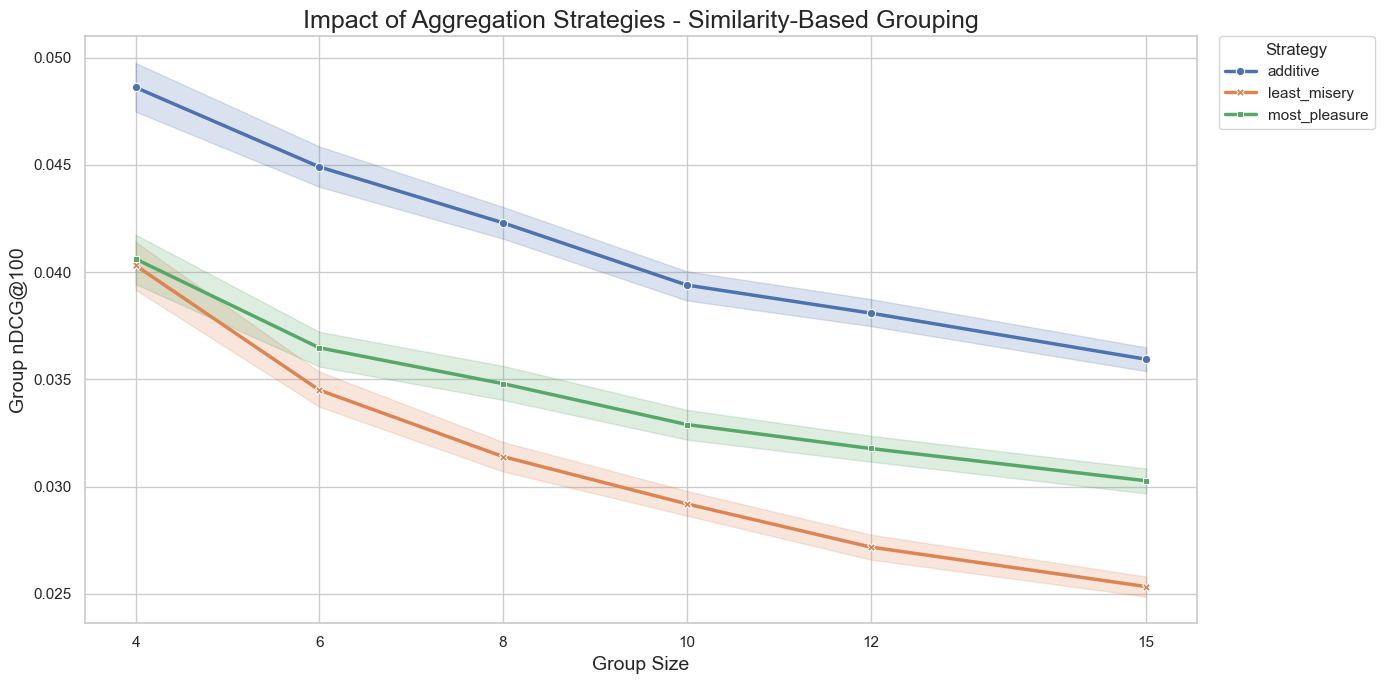

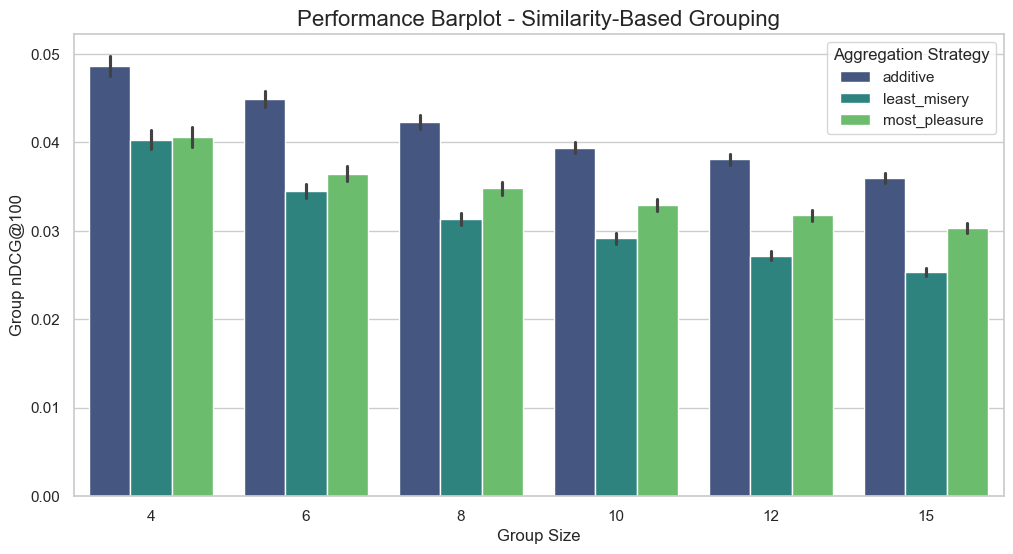


Detailed Statistics for Similarity-Based Grouping:


mean       std
Group_Size Strategy                         
4          additive       0.048615  0.041905
           least_misery   0.040317  0.039129
           most_pleasure  0.040617  0.038909
6          additive       0.044909  0.032748
           least_misery   0.034502  0.029734
           most_pleasure  0.036474  0.031247
8          additive       0.042299  0.028652
           least_misery   0.031401  0.024999
           most_pleasure  0.034801  0.028226
10         additive       0.039399  0.024525
           least_misery   0.029197  0.022005
           most_pleasure  0.032897  0.024922
12         additive       0.038092  0.022994
           least_misery   0.027185  0.019869
           most_pleasure  0.031779  0.023313
15         additive       0.035938  0.020324
           least_misery   0.025340  0.016851
           most_pleasure  0.030273  0.021231

In [15]:
# --- VISUALIZATION SETUP ---

def plot_results(df, title_suffix):
    """Helper to generate your specific plots"""
    
    # 1. Line Plot
    sns.set_theme(style="whitegrid", context="notebook")
    plt.figure(figsize=(14, 7))
    
    ax = sns.lineplot(
        data=df, 
        x="Group_Size", 
        y="nDCG", 
        hue="Strategy",
        style="Strategy",
        markers=True,
        dashes=False,
        linewidth=2.5,
        errorbar=('ci', 95)
    )

    plt.title(f"Impact of Aggregation Strategies - {title_suffix}", fontsize=18)
    plt.ylabel(f"Group nDCG@{TOP_K}", fontsize=14)
    plt.xlabel("Group Size", fontsize=14)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Strategy")
    plt.xticks(GROUP_SIZES)
    plt.tight_layout()
    plt.show()

    # 2. Bar Plot
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=df, 
        x="Group_Size", 
        y="nDCG", 
        hue="Strategy", 
        palette="viridis",
        errorbar=('ci', 95) 
    )

    plt.title(f"Performance Barplot - {title_suffix}", fontsize=16)
    plt.ylabel(f"Group nDCG@{TOP_K}", fontsize=12)
    plt.xlabel("Group Size", fontsize=12)
    plt.legend(title="Aggregation Strategy", loc='upper right')
    plt.show()
    
    # 3. Stats
    print(f"\nDetailed Statistics for {title_suffix}:")
    summary = df.groupby(['Group_Size', 'Strategy'])['nDCG'].describe()[['mean', 'std']]
    display(summary)

# --- EXECUTE PLOTTING ---

# 1. Random Grouping Results
df_random = df_results[df_results['Grouping_Method'] == 'Random']
plot_results(df_random, "Random Grouping")

# 2. Similarity Grouping Results
df_sim = df_results[df_results['Grouping_Method'] == 'Similarity']
plot_results(df_sim, "Similarity-Based Grouping")

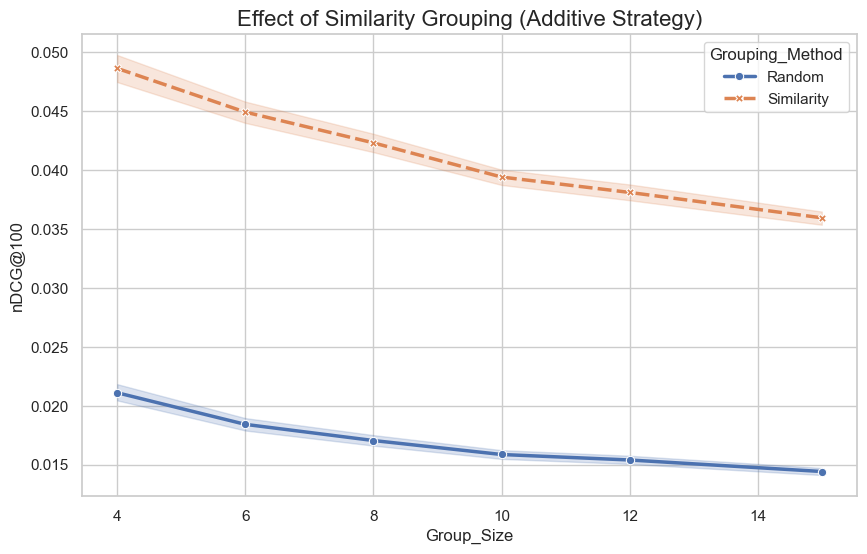

In [16]:
plt.figure(figsize=(10, 6))
# Filter for just the 'additive' (Average) strategy to keep plot clean
subset = df_results[df_results['Strategy'] == 'additive']

sns.lineplot(
    data=subset,
    x="Group_Size",
    y="nDCG",
    hue="Grouping_Method",
    style="Grouping_Method",
    markers=True,
    linewidth=2.5,
    errorbar=('ci', 95)
)
plt.title("Effect of Similarity Grouping (Additive Strategy)", fontsize=16)
plt.ylabel("nDCG@100", fontsize=12)
plt.show()